# Figures 4 and 9: chromospheric and thermal mass transfer

Run all cells in order. Figure 4 compares the reduced chromospheric integral,
the potential-based Ritter rate, and WRLOF + Ritter. Figure 9 compares the
potential and pressure-scale-height versions of the thermal rate.

Dependencies: NumPy, SciPy, pandas, and Matplotlib. Figure 9 uses the input file
`history_1p5msun.data`. PNGs are written to `paper_figures/` below the working directory.

Rates are plotted as positive magnitudes in solar masses per year. The WRLOF
term is the companion's captured wind; the comparison with nozzle transfer
adopts the efficiency interpretation in paper Section 5.1. The physical potential
is negative. The dimensionless geometry helpers return its positive opposite,
$\Omega=-\phi'$.

In [29]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
from scipy.optimize import brentq

# Edit DATA_DIR if your MESA history file is stored elsewhere.
DATA_DIR = Path('./')
OUTPUT_DIR = Path('./paper_figures')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Physical constants in CGS; functions state their input/output conversions.
G = 6.6743e-8
kB = 1.380649e-16
mp = 1.673e-24
Msun = 1.98847e33
Rsun = 6.957e10
day = 86400.0
year = 3.154e7

mpl.rcParams.update({
    'text.usetex': False,
    'axes.formatter.use_mathtext': True,
    'font.family': 'STIXGeneral',
    'mathtext.fontset': 'cm',
    'axes.unicode_minus': False,
    'axes.linewidth': 1.5,
})

## Orbital geometry and units

Masses and radii supplied to dimensional helpers are in $M_\odot$ and
$R_\odot$; periods are in days, temperatures in kelvin, and velocities in km/s.
$\mu$ is a dimensionless mean molecular weight, so $c_T^2=k_BT/(\mu m_p)$.
The public mass-ratio convention is $q=M_d/M_a$.

The volume-radius potential uses the truncated Jackson expansion with a
negative physical sign. The donor Roche radius is given by the Eggleton
approximation; the volume-radius expansion is extrapolated outside the Roche lobe.

In [15]:
def semi_major_axis(P_days, Md_Msun, Ma_Msun):
    """Keplerian separation in solar radii, for period in days."""
    P = P_days * day
    Md, Ma = Md_Msun * Msun, Ma_Msun * Msun
    return (G * (Md + Ma) * (P / (2 * np.pi))**2)**(1 / 3) / Rsun


def roche_lobe_radius(q, a_Rsun):
    """Eggleton donor volume radius in the same units as separation a_Rsun."""
    q13, q23 = q**(1 / 3), q**(2 / 3)
    return a_Rsun * 0.49 * q23 / (0.6 * q23 + np.log(1 + q13))


def isothermal_sound_speed(T, mu=1.0):
    """Isothermal sound speed in km/s; mu is dimensionless."""
    return np.sqrt(kB * T / (mu * mp)) / 1e5


def potential_rv_dimensionless(rv_a, q):
    """Return positive Omega=-phi' at volume radius rv_a=R_V/a."""
    inverse_q = 1.0 / q
    a1 = (1.0 + inverse_q) / 3.0
    a2 = (4.0 / 45.0) * (
        (1.0 + inverse_q)**2 + 9 * inverse_q**2
        + 3 * inverse_q * (1.0 + inverse_q)
    )
    constant = inverse_q + inverse_q / (2.0 * (1.0 + q))
    return constant + 1.0 / rv_a + a1 * rv_a**2 + a2 * rv_a**5


def potential_rv(r_v_Rsun, a_Rsun, Md_Msun, Ma_Msun):
    """Negative physical volume-radius potential in (km/s)^2."""
    # Convert the radius, separation, and masses to CGS before evaluating the potential.
    r_v, a = r_v_Rsun * Rsun, a_Rsun * Rsun
    Md, Ma = Md_Msun * Msun, Ma_Msun * Msun
    a1 = (Md + Ma) / (3.0 * Md)
    a2 = (4.0 / 45.0) * ((Md + Ma)**2 + 9 * Ma**2 + 3 * Ma * (Md + Ma)) / Md**2
    constant = -(G * Ma / a + G * Ma**2 / (2.0 * a * (Md + Ma)))
    return (constant - G * Md / r_v * (1 + a1 * (r_v / a)**3 + a2 * (r_v / a)**6)) / 1e10


def roche_potential(x, y, z, q):
    """Positive Omega=-phi' with donor at x=0, accretor at x=1, and a=1."""
    inverse_q = 1.0 / q
    x_cm = inverse_q / (1.0 + inverse_q)
    r1 = np.sqrt(x**2 + y**2 + z**2)
    r2 = np.sqrt((x - 1.0)**2 + y**2 + z**2)
    return 1.0 / r1 + inverse_q / r2 + 0.5 * (1.0 + inverse_q) * ((x - x_cm)**2 + y**2)


def lagrange_point(q, point):
    """Return x/a for L1 between the stars, or L2 beyond the accretor."""
    inverse_q = 1.0 / q
    x_cm = inverse_q / (1.0 + inverse_q)

    def derivative(x):
        return (-x / abs(x)**3 - inverse_q * (x - 1.0) / abs(x - 1.0)**3
                + (1.0 + inverse_q) * (x - x_cm))

    brackets = {'L1': (1e-6, 1.0 - 1e-6), 'L2': (1.0 + 1e-6, 5.0)}
    return brentq(derivative, *brackets[point], xtol=1e-10)


def nozzle_coefficients(q):
    """Dimensionless quadratic B,C and quartic C3 coefficients (draft A3)."""
    x = lagrange_point(q, 'L1')
    inverse_q = 1.0 / q
    g = 1.0 / x**3 + inverse_q / (1.0 - x)**3
    higher = 1.0 / x**5 + inverse_q / (1.0 - x)**5
    return (g - inverse_q - 1.0) / 2.0, g / 2.0, -3.0 * higher / 8.0


def dAdphi_linear(Md, Ma, sma):
    """Quadratic nozzle dA/dphi in seconds squared, for dimensional phi."""
    B, C, _ = nozzle_coefficients(Md / Ma)
    scale = G * Md * Msun / (sma * Rsun)
    return np.pi * (sma * Rsun)**2 / (scale * np.sqrt(B * C))

## Mass-transfer prescriptions

The chromospheric prescription uses the midpoint area and radius approximation
of Appendix C, a 200-point radius lookup, and 1,000 shock-speed grid edges out to
$10v_{\rm con}$. The shock-speed distribution is half-normal.

The potential integral evaluates the clamped exponential analytically between
L1 and L2. The geometric density factor and nozzle-area derivative are evaluated
at the midpoint potential. Conversion to a dimensional rate combines the
half-normal normalization with the sonic factor $e^{-1/2}$, giving the prefactor
$\sqrt{2/(\pi e)}$. The thermal prescriptions use either a potential difference
or an effective pressure scale height in the density exponential.

In [16]:
def chromosphere_integral(q, f_RL, cT_prime, vcon_prime, vs_res=1000):
    """Reduced dimensionless Appendix C integral, excluding PDF normalization.

    Speeds are divided by sqrt(G*Md/a). Intended for the q>=1 Figure 4 grid,
    whose first outer opening is L2. f_RL is R_ph/R_L, not R_ph/a.
    """
    if q < 1.0:
        raise ValueError('This figure prescription assumes q=Md/Ma >= 1; q<1 requires the L3 opening.')
    R_L = roche_lobe_radius(q, 1.0)
    R_ph = f_RL * R_L
    phi_L1 = -roche_potential(lagrange_point(q, 'L1'), 0.0, 0.0, q)
    phi_L2 = -roche_potential(lagrange_point(q, 'L2'), 0.0, 0.0, q)
    phi_mid = (phi_L1 + phi_L2) / 2.0
    phi_ph = -potential_rv_dimensionless(R_ph, q)

    # Find the radius corresponding to the midpoint potential on a 200-point grid.
    radius_grid = np.linspace(R_L, 2.0 * R_L, 200)
    potential_grid = -potential_rv_dimensionless(radius_grid, q)
    radius_mid = radius_grid[np.argmin(np.abs(potential_grid - phi_mid))]

    speed_edges = np.linspace(0.0, 10.0 * vcon_prime, vs_res)
    speed = (speed_edges[1:] + speed_edges[:-1]) / 2.0
    speed_squared = speed**2
    total_squared = speed_squared + cT_prime**2
    gaussian = np.exp(-speed_squared / (2.0 * vcon_prime**2))

    B, C, C3 = nozzle_coefficients(q)
    area0 = np.pi / np.sqrt(B * C)
    area1 = area0 * C3 * (3 * B**2 + 2 * B * C + 3 * C**2) / (4.0 * B**2 * C**2)
    darea_dphi = area0 - area1 * (phi_mid - phi_L1)

    # Integral of exp[-max(phi-phi_ph,0)/total_squared] from L1 to L2.
    # expm1 avoids subtracting nearly equal exponentials at large total speed.
    lower_gap = max(phi_L1 - phi_ph, 0.0)
    upper_gap = max(phi_L2 - phi_ph, 0.0)
    exponential_difference = np.exp(-lower_gap / total_squared) * (
        -np.expm1(-(upper_gap - lower_gap) / total_squared)
    )
    potential_integral = (total_squared * exponential_difference
                          + max(phi_ph - phi_L1, 0.0) - max(phi_ph - phi_L2, 0.0))
    geometry = (R_ph / radius_mid)**(2.0 * speed_squared / total_squared)
    return np.sum(gaussian * np.diff(speed_edges) * np.sqrt(total_squared)
                  * geometry * darea_dphi * potential_integral)


def ritter_mdot(Rd, Md, Ma, P_days, rhoph, T, mu):
    """Potential-based thermal mass loss in Msun/year; density in g/cm^3."""
    cT = isothermal_sound_speed(T, mu)
    sma = semi_major_axis(P_days, Md, Ma)
    R_L = roche_lobe_radius(Md / Ma, sma)
    phi_R = potential_rv(Rd, sma, Md, Ma)
    phi_L = potential_rv(R_L, sma, Md, Ma)
    # Saturate the optically thin rate at Roche contact.
    gap = np.maximum(phi_L - phi_R, 0.0)
    rate_cgs = (np.exp(-0.5) * (cT * 1e5)**3 * np.exp(-gap / cT**2)
                * rhoph * dAdphi_linear(Md, Ma, sma))
    return rate_cgs * year / Msun


def ritter_mdot_scale_height(Rd, Md, Ma, P_days, rhoph, Psurf, T, mu):
    """MESA-style scale-height comparison in Msun/year.

    Psurf is gas/EOS pressure in dyn/cm^2. The fitted gamma and F1 use
    accretor/donor mass ratio, opposite to the public geometry convention.
    """
    cT = isothermal_sound_speed(T, mu)
    sma = semi_major_axis(P_days, Md, Ma)
    R_L = roche_lobe_radius(Md / Ma, sma)
    gravity = G * Md * Msun / (Rd * Rsun)**2
    H_p = Psurf / (gravity * rhoph)

    inverse_q = Ma / Md
    q_fit = np.clip(inverse_q, 0.5, 10.0)
    F1 = 1.23 + 0.5 * np.log10(q_fit)
    rate0 = (2.0 * np.pi * np.exp(-0.5) * (cT * 1e5)**3
             * (R_L * Rsun)**3 / (G * Md * Msun) * rhoph * F1)
    log_q = np.log10(np.clip(inverse_q, 0.04, 20.0))
    if log_q < 0.0:
        gamma = 0.954 + 0.025 * log_q - 0.038 * log_q**2
    else:
        gamma = 0.954 + 0.039 * log_q + 0.114 * log_q**2
    H_effective = H_p / gamma
    exponent = np.minimum((Rd - R_L) * Rsun / H_effective, 0.0)
    return rate0 * np.exp(exponent) * year / Msun

## Figure 4: fixed donor, varying orbital period

The parameter cell specifies the donor and accretor masses, donor radius,
photospheric density, temperature, composition, orbital-period grid, and
convective-speed ratios $f_{\rm con}=v_{\rm con}/v_{\rm esc}$.
The thermal and chromospheric rates use the same mean molecular weight.

Varying the orbital period changes the Roche filling factor while the donor
properties remain fixed. The plot annotations and legend are generated from
these inputs. The WRLOF contribution uses a fixed wind rate and a capture
fraction clipped to the interval $[0,0.5]$.

In [17]:
# Figure 4 parameters; edit here and the figure annotations update automatically.
Md, Ma = 1.0, 0.5                 # Solar masses.
Rd = 150.0                        # Solar radii.
rhoph, T, mu = 3.5e-9, 3300.0, 1.31
periods = np.linspace(590.0, 4500.0, 500)
f_cons = [0.1, 0.05, 0.02]

q = Md / Ma
v_escape = np.sqrt(2.0 * G * Md * Msun / (Rd * Rsun)) / 1e5
r_L1s = roche_lobe_radius(q, semi_major_axis(periods, Md, Ma))
ritter_rates = ritter_mdot(Rd, Md, Ma, periods, rhoph, T, mu)
chromosphere_rates = np.zeros((len(periods), len(f_cons)))

for i, period in enumerate(periods):
    separation = semi_major_axis(period, Md, Ma)
    potential_scale = G * Md * Msun / (separation * Rsun) / 1e10  # (km/s)^2.
    velocity_scale = np.sqrt(potential_scale)
    cT_prime = isothermal_sound_speed(T, mu) / velocity_scale
    for j, f_con in enumerate(f_cons):
        vcon = f_con * v_escape
        integral = chromosphere_integral(q, Rd / r_L1s[i], cT_prime, vcon / velocity_scale)
        # Half-normal PDF sqrt(2/pi)/vcon and sonic factor exp(-1/2).
        # GMd/a * a^2 converts the dimensionless speed-potential-area integral.
        rate_cgs = (integral * np.sqrt(2.0 / (np.pi * np.e)) / (vcon * 1e5)
                    * rhoph * potential_scale * 1e10 * (separation * Rsun)**2)
        chromosphere_rates[i, j] = rate_cgs * year / Msun

# WRLOF capture fraction, using q=Md/Ma, clipped to its adopted [0, 0.5] range.
T_cond = 1500.0
R_wind = 0.5 * Rd * (T / T_cond)**2.5
x = R_wind / r_L1s
beta_capture = np.clip(25.0 / (9.0 * q**2) * (-0.284 * x**2 + 0.918 * x - 0.234), 0.0, 0.5)
mdot_wind = 1e-6  # Msun/year; fixed for this comparison.
wrlof_plus_ritter = beta_capture * mdot_wind + ritter_rates

# WRLOF capture fraction, using q=Md/Ma, clipped to its adopted [0, 0.5] range.
T_cond = 1200.0
R_wind = 0.5 * Rd * (T / T_cond)**2.5
x = R_wind / r_L1s
beta_capture = np.clip(25.0 / (9.0 * q**2) * (-0.284 * x**2 + 0.918 * x - 0.234), 0.0, 0.5)
mdot_wind = 1e-6  # Msun/year; fixed for this comparison.
wrlof_plus_ritter_lowtd = beta_capture * mdot_wind + ritter_rates

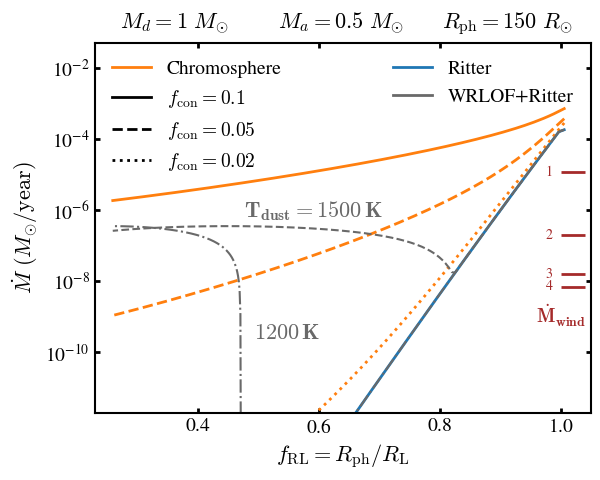

In [18]:
fig, ax = plt.subplots(figsize=(6.4, 4.8))
fill_factors = Rd / r_L1s
ax.plot(fill_factors, ritter_rates, color='C0', linewidth=2)
styles = ['-', '--', ':']
for j, style in enumerate(styles):
    ax.plot(fill_factors, chromosphere_rates[:, j], color='C1', linestyle=style, linewidth=2)
ax.plot(fill_factors, wrlof_plus_ritter, color='dimgrey', linestyle='--', linewidth=1.5)
ax.plot(fill_factors, wrlof_plus_ritter_lowtd, color='dimgrey', linestyle='-.', linewidth=1.5)

style_handles = [Line2D([0], [0], color='C1', lw=2, label='Chromosphere')]
style_handles += [Line2D([0], [0], color='black', lw=2, linestyle=style,
                         label=rf'$f_{{\rm con}}={f_con:g}$')
                  for f_con, style in zip(f_cons, styles)]
style_legend = ax.legend(handles=style_handles, loc='upper left', fontsize=14, framealpha=0.0, ncols=1)
ax.legend(handles=[Line2D([0], [0], color='C0', lw=2, label='Ritter'),
                   Line2D([0], [0], color='dimgrey', lw=2, linestyle='-', label=r'WRLOF+Ritter')],
          fontsize=14, loc='upper right', framealpha=0.0)
ax.add_artist(style_legend)

ax.set(xscale='linear', yscale='log', xlim=(0.22, 1.01), ylim=(2e-12, 5e-2))
ax.set_ylabel(r'$\dot{M}~(M_{\odot}/{\rm year})$', fontsize=16)
ax.set_xlabel(r'$f_{\rm RL}=R_{\rm ph}/R_{\rm L}$', fontsize=16)
ax.tick_params(which='both', direction='in', top=True, right=True, labelsize=14, width=2)
ax.text(0.05, 1.04, rf'$M_d={Md:g}~M_{{\odot}}$', transform=ax.transAxes, fontsize=16)
ax.text(0.37, 1.04, rf'$M_a={Ma:g}~M_{{\odot}}$', transform=ax.transAxes, fontsize=16)
ax.text(0.7, 1.04, rf'$R_{{\rm ph}}={Rd:g}~R_{{\odot}}$', transform=ax.transAxes, fontsize=16)

ax.text(
    0.3, 0.53,
    r'$\mathbf{{T_{\rm \bf dust}=\mathbf{1500}\,K}}$',
    transform=ax.transAxes,
    fontsize=16,
    color='dimgrey',
    usetex=False,
)

ax.text(
    0.32, 0.2,
    r'$\mathbf{{\mathbf{1200}\,K}}$',
    transform=ax.transAxes,
    fontsize=16,
    color='dimgrey',
    usetex=False,
)


Td_ref = 1200  # change to 1200 if desired

full, reduced = {
    1200: (1.15e-5, 7.04e-9),
    1500: (3.01e-5, 5.09e-8),
}[Td_ref]

# Reimers, Bloecker, Full Chromospheric, Reduced Chromospheric
reference_rates = [1.55e-8, 2.01e-7, full, reduced]

ax.hlines(
    reference_rates,
    xmin=1.0, xmax=1.04,
    colors=['brown', 'brown', 'brown', 'brown'],
    linewidths=2,
    zorder=20,
)

for i, rate in enumerate(sorted(reference_rates, reverse=True), start=1):
    ax.annotate(
        str(i),
        xy=(1.0, rate),
        xytext=(-6, 0),
        textcoords='offset points',
        ha='right', va='center',
        fontsize=10, color='brown',
        zorder=21,
    )
    
ax.annotate(
    r'$\mathbf{\dot{M}_{\rm \bf wind}}$',
    xy=(1.0, min(reference_rates)+5e-9),
    xytext=(0, -18),
    textcoords='offset points',
    ha='center', va='top',
    fontsize=14, color='brown',
    zorder=21,
)

ax.set_xlim(0.23, 1.05)
#fig.savefig(OUTPUT_DIR / 'mdot_1msun_q2_fixedRd_with_wind.png', dpi=200, bbox_inches='tight')
plt.show()

## Figure 4b: fixed orbital period, evolving AGB donor

Use the 1 solar-mass no-wind history after central helium exhaustion:
`center_h1 < 0.01` and `center_he4 < 1e-4`. All selected models are used; thermal pulses can revisit the same filling factor.
The figure groups models into bins of width 0.05 in $f_{\rm RL}$. Each curve
shows the unweighted median of the models in each bin, with capped vertical
error bars spanning the full minimum-to-maximum range.

The period and companion mass are fixed. The donor mass, radius, luminosity,
photospheric density, temperature, mean molecular weight, and convective speed
come from each history row. The default period is 5,000 days with a 0.5 solar-mass companion.
The largest AGB models slightly overfill their Roche lobe; they remain included
in the final filling-factor bin.

Full Chromospheric uses MESA `vcon_surf`; Reduced Chromospheric uses half of it.
As in Figure 4, all prescriptions use the isothermal sound speed
$c_T=\sqrt{k_BT/(\mu m_p)}$, not MESA's adiabatic `cs_surf`.
Solid lines show binary mass transfer; dashed lines show isolated-star winds.
The wind dust temperature defaults to 1,200 K and the Bloecker factor to 0.2.
These are rates evaluated on the supplied no-wind track, with no feedback on
the donor or orbit. The original Figure 4 and Figure 9 cells are retained.


In [19]:
# Fixed-orbit AGB comparison; edit these parameters.
P_agb = 5000.0          # days
Ma_agb = 0.5            # solar masses
Td_agb = 1200.0         # K, for the chromospheric winds
eta_bloecker_agb = 0.2

history_agb = pd.read_csv(DATA_DIR / 'history_1msun_nowind.data',
                          skiprows=5, sep=r'\s+')
agb = history_agb[(history_agb['center_h1'] < 0.01)
                  & (history_agb['center_he4'] < 1e-4)].copy()

Md_agb = agb['star_mass'].to_numpy()
R_agb = 10.0**agb['log_R'].to_numpy()
L_agb = 10.0**agb['log_L'].to_numpy()
T_agb = 10.0**agb['log_Teff'].to_numpy()
rho_agb = agb['rho_surf'].to_numpy()
mu_agb = agb['mu_surf'].to_numpy()
vcon_agb = agb['vcon_surf'].to_numpy() / 1e5  # cm/s -> km/s

separation_agb = semi_major_axis(P_agb, Md_agb, Ma_agb)
RL_agb = roche_lobe_radius(Md_agb / Ma_agb, separation_agb)
fill_agb = R_agb / RL_agb


TypeError: unsupported operand type(s) for /: 'str' and 'str'

In [20]:
def chromosphere_mdot(Rd, Md, Ma, P_days, rhoph, T, mu, vcon):
    """Figure 4 transfer in Msun/year; radii/masses solar, vcon in km/s."""
    sma = semi_major_axis(P_days, Md, Ma)
    RL = roche_lobe_radius(Md / Ma, sma)
    potential_scale = G * Md * Msun / (sma * Rsun) / 1e10
    velocity_scale = np.sqrt(potential_scale)
    cT = isothermal_sound_speed(T, mu)
    integral = chromosphere_integral(
        Md / Ma, Rd / RL, cT / velocity_scale, vcon / velocity_scale
    )
    rate_cgs = (integral * np.sqrt(2.0 / (np.pi * np.e)) / (vcon * 1e5)
                * rhoph * potential_scale * 1e10 * (sma * Rsun)**2)
    return rate_cgs * year / Msun


def bloecker_wind(Md, Rd, L, eta=0.2):
    """Masses, radii, luminosities in solar units; return Msun/year."""
    reimers_baseline = 4.0e-13 * L * Rd / Md
    return eta * 4.83e-9 * Md**(-2.1) * L**2.7 * reimers_baseline


def chromospheric_wind(Rd, Md, rhoph, T, mu, vcon, Td=1200.0):
    """Isolated-star wind in Msun/year; radii/masses solar, vcon in km/s."""
    Rph = Rd * Rsun
    vcon_cgs = vcon * 1e5
    cT = isothermal_sound_speed(T, mu) * 1e5
    vesc2 = 2.0 * G * Md * Msun / Rph
    dust_q = 2.0 * (Td / T)**4
    Rdust = Rph / np.sqrt(dust_q * (2.0 - dust_q))

    # Simple midpoint integration over shock speeds, out to 40*vcon.
    speed_edges = np.linspace(0.0, 40.0 * vcon_cgs, 1001)
    speed = (speed_edges[:-1] + speed_edges[1:]) / 2.0
    total2 = speed**2 + cT**2
    density = (rhoph / np.sqrt(np.e)
               * np.exp(-vesc2 / (2.0 * total2) * (1.0 - Rph / Rdust))
               * (Rph / Rdust)**(2.0 * speed**2 / total2))
    pdf = (np.sqrt(2.0 / np.pi) / vcon_cgs
           * np.exp(-speed**2 / (2.0 * vcon_cgs**2)))
    flux = np.sum(density * pdf * np.sqrt(total2) * np.diff(speed_edges))
    return 4.0 * np.pi * Rdust**2 * flux * year / Msun


In [21]:
ritter_agb = np.zeros(len(agb))
chromosphere_agb = np.zeros((len(agb), 2))
chromosphere_wind_agb = np.zeros((len(agb), 2))
bloecker_agb = bloecker_wind(Md_agb, R_agb, L_agb, eta_bloecker_agb)

for i, (Md_i, R_i, rho_i, T_i, mu_i, vcon_i) in enumerate(zip(
        Md_agb, R_agb, rho_agb, T_agb, mu_agb, vcon_agb)):
    ritter_agb[i] = ritter_mdot(R_i, Md_i, Ma_agb, P_agb, rho_i, T_i, mu_i)
    for j, factor in enumerate([1.0, 0.5]):
        vcon_i_used = factor * vcon_i
        chromosphere_agb[i, j] = chromosphere_mdot(
            R_i, Md_i, Ma_agb, P_agb, rho_i, T_i, mu_i, vcon_i_used
        )
        chromosphere_wind_agb[i, j] = chromospheric_wind(
            R_i, Md_i, rho_i, T_i, mu_i, vcon_i_used, Td_agb
        )


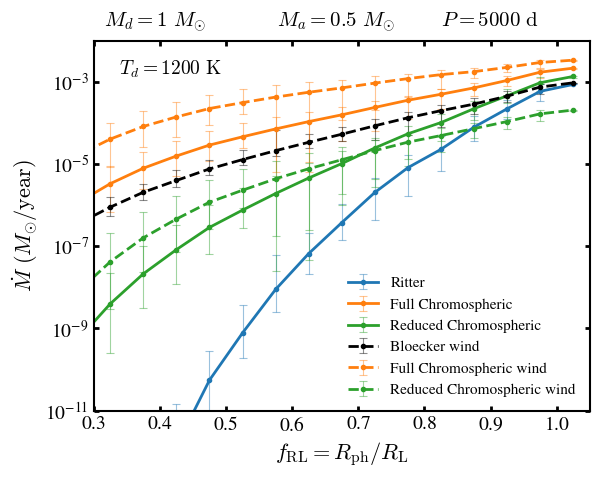

In [22]:
# Bin every model in f_RL intervals of width 0.05.
bin_width = 0.05
bin_edges = np.arange(0.0, np.max(fill_agb) + 2*bin_width, bin_width)


def bin_rates(fill, rates, edges):
    centers, medians, lower, upper = [], [], [], []
    for left, right in zip(edges[:-1], edges[1:]):
        values = rates[(fill >= left) & (fill < right)]
        if len(values) == 0:
            continue
        median = np.median(values)
        centers.append((left + right) / 2)
        medians.append(median)
        lower.append(median - values.min())
        upper.append(values.max() - median)
    return np.array(centers), np.array(medians), np.array([lower, upper])


series = [
    (ritter_agb, 'C0', '-', 'Ritter'),
    (chromosphere_agb[:, 0], 'C1', '-', 'Full Chromospheric'),
    (chromosphere_agb[:, 1], 'C2', '-', 'Reduced Chromospheric'),
    (bloecker_agb, 'black', '--', 'Bloecker wind'),
    (chromosphere_wind_agb[:, 0], 'C1', '--', 'Full Chromospheric wind'),
    (chromosphere_wind_agb[:, 1], 'C2', '--', 'Reduced Chromospheric wind'),
]

fig, ax = plt.subplots(figsize=(6.4, 4.8))
for rates, color, style, label in series:
    centers, medians, errors = bin_rates(fill_agb, rates, bin_edges)
    ax.errorbar(centers, medians, yerr=errors,
                color=color, linestyle=style, linewidth=2,
                marker='o', markersize=3,
                ecolor=mpl.colors.to_rgba(color, 0.45),
                elinewidth=0.8, capsize=3, capthick=0.8, label=label)

ax.set(xscale='linear', yscale='log', xlim=(0.3, 1.05), ylim=(1e-11, 1e-2))
ax.set_ylabel(r'$\dot{M}~(M_{\odot}/{\rm year})$', fontsize=16)
ax.set_xlabel(r'$f_{\rm RL}=R_{\rm ph}/R_{\rm L}$', fontsize=16)
ax.tick_params(which='both', direction='in', top=True, right=True, labelsize=14, width=2)
ax.legend(loc='lower right', fontsize=11, framealpha=0.0)
ax.text(0.02, 1.04, rf'$M_d={Md_agb[0]:g}~M_{{\odot}}$',
        transform=ax.transAxes, fontsize=15)
ax.text(0.37, 1.04, rf'$M_a={Ma_agb:g}~M_{{\odot}}$',
        transform=ax.transAxes, fontsize=15)
ax.text(0.70, 1.04, rf'$P={P_agb:g}~{{\rm d}}$',
        transform=ax.transAxes, fontsize=15)
ax.text(0.05, 0.91, rf'$T_d={Td_agb:g}~{{\rm K}}$',
        transform=ax.transAxes, fontsize=14)

fig.savefig(OUTPUT_DIR / 'agb_fixed_period_binned.png', dpi=200, bbox_inches='tight')
plt.show()


## Figure 9: potential versus scale height

Select the sample nearest $200R_\odot$ from `history_1p5msun.data` and read its
surface density, effective temperature, pressure, and mean molecular weight.
Use these surface properties in a parameterized binary comparison with
$M_d=1M_\odot$ and $M_a=0.6M_\odot$ over periods of 1,000–2,500 days.
The two curves evaluate the potential-based and effective-scale-height
prescriptions at the same Roche filling factors.

In [27]:
history_path = './history_1p5msun.data'
history = pd.read_csv(history_path, skiprows=5, sep=r'\s+')
radii = 10.0**history['log_R'].to_numpy()
sample = history.iloc[np.argmin(np.abs(radii - 200.0))]

Rd9 = 10.0**sample['log_R']
rho9 = sample['rho_surf']           # g/cm^3.
T9 = 10.0**sample['log_Teff']        # Effective temperature in K.
mu9 = sample['mu_surf']             # Dimensionless.
pressure9 = sample['Peos_surf']     # dyn/cm^2.
Md9, Ma9 = 1.0, 0.6
periods9 = np.linspace(1000.0, 2500.0, 100)
r_lobe9 = roche_lobe_radius(Md9 / Ma9, semi_major_axis(periods9, Md9, Ma9))
potential_rates9 = ritter_mdot(Rd9, Md9, Ma9, periods9, rho9, T9, mu9)
scale_height_rates9 = ritter_mdot_scale_height(Rd9, Md9, Ma9, periods9, rho9, pressure9, T9, mu9)

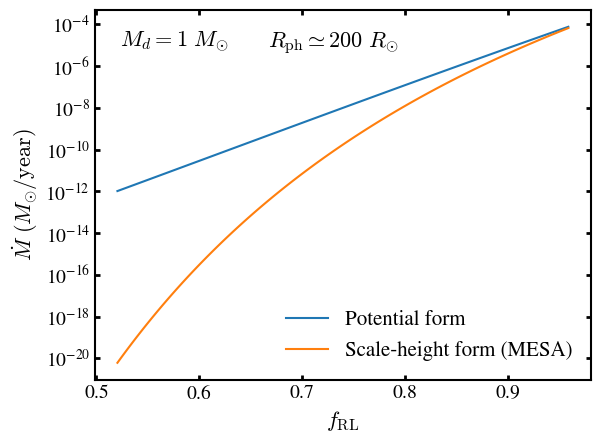

In [28]:
fig, ax = plt.subplots(figsize=(6.4, 4.8))
ax.plot(Rd9 / r_lobe9, potential_rates9, label='Potential form')
ax.plot(Rd9 / r_lobe9, scale_height_rates9, label='Scale-height form (MESA)')
ax.set_yscale('log')
ax.set_ylabel(r'$\dot{M}~(M_{\odot}/{\rm year})$', fontsize=16)
ax.set_xlabel(r'$f_{\rm RL}$', fontsize=16)
ax.tick_params(which='both', direction='in', top=True, right=True, labelsize=14, width=2)
ax.legend(loc='lower right', fontsize=15, framealpha=0.0)
ax.text(0.05, 0.9, rf'$M_d={Md9:g}~M_{{\odot}}$', transform=ax.transAxes, fontsize=16)
ax.text(0.35, 0.9, rf'$R_{{\rm ph}}\simeq{Rd9:.0f}~R_{{\odot}}$', transform=ax.transAxes, fontsize=16)
fig.savefig(OUTPUT_DIR / 'ritter_comp_radvpot.png', dpi=200, bbox_inches='tight')
plt.show()